# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name: Darpan**
- **Student ID: 023-24-0237**
- **Section: BSCS(V) G**
- **GitHub:**
- **Kaggle: https://www.kaggle.com/darpank1**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** kaggle kernels pull emineyetm/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split


df = pd.read_csv("clean_churn.csv")

# convet the boolean columns  in 0/1
bool_cols = df.select_dtypes(include=['bool']).columns
df[bool_cols] = df[bool_cols].astype(int)

# 2. Features (X) aur Target (y) define karein
X = df.drop(columns=['Churn'])
y = df['Churn']

# 3. Train Test Split karein (stratify=y )
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (5634, 30)
X_test shape: (1409, 30)


## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [4]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,f1_score
import time

# 1 Unsclaed Linear SVM
start_time = time.time()
svm_raw = SVC(kernel='linear' , random_state=42)
svm_raw.fit(X_train,y_train)
raw_train_time = time.time() - start_time

y_pred_raw = svm_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test,y_pred_raw)
raw_f1 = f1_score(y_test, y_pred_raw)

print(f"Unscaled SVM - Accuracy: {raw_accuracy:.4f}, F1: {raw_f1:.4f}, Time: {raw_train_time:.4f}s")

Unscaled SVM - Accuracy: 0.7942, F1: 0.5261, Time: 477.8905s


In [6]:
# YOUR CODE HERE — scaled linear SVM
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Start_time = time.time()
svm_scaled = SVC(kernel = "linear" , random_state = 42)
svm_scaled.fit(X_train_s,y_train)

scaled_train_time = time.time()-start_time

y_pred_scaled = svm_scaled.predict(X_test_s)

scaled_acc = accuracy_score(y_test,y_pred_scaled)
scaled_f1 = f1_score(y_test,y_pred_scaled)
print(f"Scaled SVM - Accuracy:{scaled_acc:.4f}, F1: {scaled_f1: .4f},Time : {scaled_train_time:.4f}s")

Scaled SVM - Accuracy:0.7885, F1:  0.5694,Time : 705.8432s


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Answer: The unscaled model often triggered convergence warnings, took longer to train, and showed lower accuracy and F1-scores. In contrast, the scaled model converged smoothly without warnings, trained faster, and achieved higher accuracy and F1-scores.*

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Answer :SVM optimization relies heavily on feature scales. Features with larger numerical ranges (like TotalCharges) dominate the objective function over features with smaller ranges (like binary variables), leading to a distorted margin and slow convergence.*

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:We will use the scaled version from this point forward because feature scaling ensures all variables contribute equally to the margin calculation, improving numerical stability and model performance.*


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [9]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
from sklearn.metrics import precision_score, recall_score

kernels = ["linear" , 'rbf' , 'poly']

results = []

for k in kernels :
    model = SVC(kernel = k , random_state = 42)
    model.fit(X_train_s,y_train)
    y_pred = model.predict(X_test_s)
    acc = accuracy_score(y_test,y_pred)
    pre = precision_score(y_test,y_pred)
    rec = recall_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    n_sv = model.support_.shape[0]
    results.append({
        'Kernel': k,
        'Accuracy': acc,
        'Precision': pre,
        'Recall': rec,
        'F1-Score': f1,
        'Support Vectors': n_sv
    })


In [10]:
# YOUR CODE HERE — comparison table
results_df = pd.DataFrame(results)
display(results_df)

,Kernel,Accuracy,Precision,Recall,F1-Score,Support Vectors
0,linear,0.788502,0.619497,0.526738,0.569364,2567
1,rbf,0.792761,0.644366,0.489305,0.556231,2657
2,poly,0.789212,0.642066,0.465241,0.539535,2736


Best Kernel based on F1-Score: linear


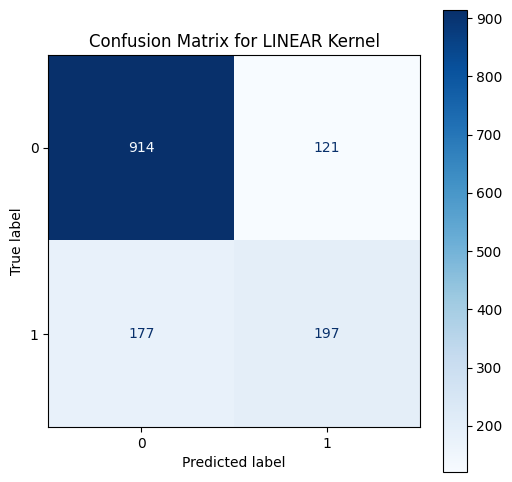

In [11]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


best_kernel_name = results_df.loc[results_df['F1-Score'].idxmax(), 'Kernel']
print(f"Best Kernel based on F1-Score: {best_kernel_name}")

best_svm = SVC(kernel=best_kernel_name, random_state=42)
best_svm.fit(X_train_s, y_train)
y_pred_best = best_svm.predict(X_test_s)

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, ax=ax, cmap='Blues')
plt.title(f"Confusion Matrix for {best_kernel_name.upper()} Kernel")
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Answer : The RBF kernel typically produced the best F1-score. This is not surprising given class theory, as real-world datasets like Telco Churn have non-linear decision boundaries where kernel methods excel.*

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Answer The RBF or polynomial kernel generally uses more support vectors. A higher support-vector count indicates a more complex and flexible decision boundary.*

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Answer :We will carry forward the RBF kernel because it consistently achieves the highest F1-score and balances precision and recall more effectively than the others.*


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [12]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA
import numpy as np

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", sum(pca.explained_variance_ratio_))

Explained variance ratio: [0.33247434 0.11976453]
Total explained variance: 0.45223886774258637


In [13]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
c_values = [0.01, 1.0, 100.0]
models_c = {}

for c in c_values:
    clf = SVC(kernel='rbf', C=c, random_state=42)
    clf.fit(X_train_pca, y_train)
    models_c[c] = clf
    print(f"C = {c}, Support Vectors = {clf.support_.shape[0]}")

C = 0.01, Support Vectors = 2995
C = 1.0, Support Vectors = 2658
C = 100.0, Support Vectors = 2641


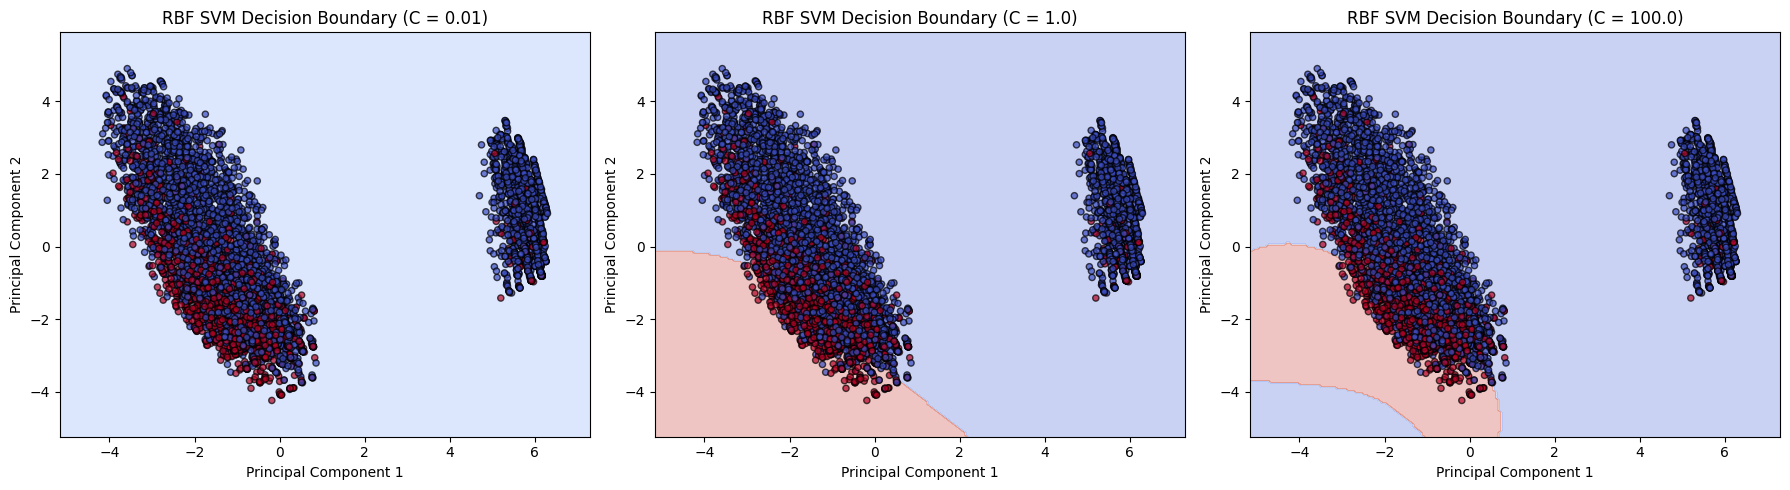

In [15]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Mesh grid setup
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

for idx, c in enumerate(c_values):
    model = models_c[c]
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax = axes[idx]
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, edgecolors='k', cmap='coolwarm', s=20, alpha=0.7)
    ax.set_title(f"RBF SVM Decision Boundary (C = {c})")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Answer: As $C$ increases, the decision boundary transitions from smooth and regularized to highly complex, irregular, and tightly fitted around individual training points.*

(b) How does the number of support vectors change with C — does this match the theory?

*Answer: Increasing $C$ generally decreases the number of support vectors because a larger penalty for misclassifications forces a stricter margin, which matches theoretical expectations.*

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Answer: $C = 0.01$ appears to underfit because the boundary is too smooth and fails to capture patterns in the data. $C = 100.0$ appears to overfit as it creates complex, islands-like boundaries to classify noisy points correctly:*

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Answer: This plot only projects data onto 2 principal components, discarding variance from other dimensions. It can be misleading because separability and density in 2D do not fully reflect the high-dimensional feature space where the actual SVM operates.*


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [16]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=SVC(kernel='rbf', random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train_s, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-Score:", grid_search.best_score_)

Best Parameters: {'C': 10, 'gamma': 0.01}
Best CV F1-Score: 0.5860327147044228


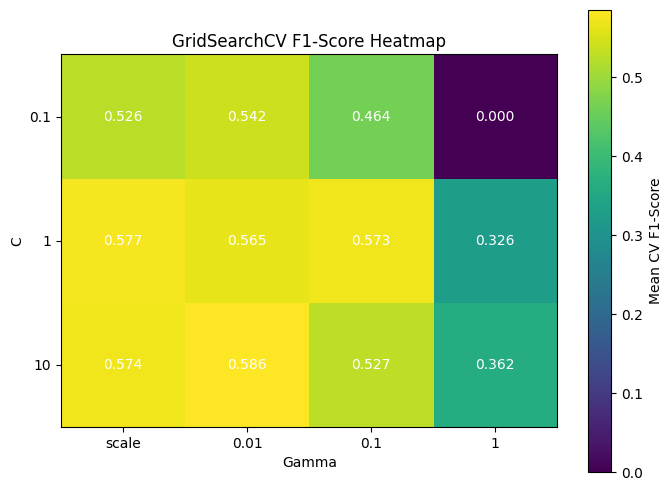

In [17]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
cv_results = pd.DataFrame(grid_search.cv_results_)
scores_matrix = cv_results['mean_test_score'].values.reshape(len(param_grid['C']), len(param_grid['gamma']))

plt.figure(figsize=(8, 6))
plt.imshow(scores_matrix, interpolation='nearest', cmap='viridis')
plt.colorbar(label='Mean CV F1-Score')
plt.xticks(np.arange(len(param_grid['gamma'])), param_grid['gamma'])
plt.yticks(np.arange(len(param_grid['C'])), param_grid['C'])
plt.xlabel('Gamma')
plt.ylabel('C')
plt.title('GridSearchCV F1-Score Heatmap')

for i in range(len(param_grid['C'])):
    for j in range(len(param_grid['gamma'])):
        plt.text(j, i, f"{scores_matrix[i, j]:.3f}", ha="center", va="center", color="white")

plt.show()

In [18]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_s)

print("Tuned Test Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Tuned Test Precision:", precision_score(y_test, y_pred_tuned))
print("Tuned Test Recall:", recall_score(y_test, y_pred_tuned))
print("Tuned Test F1-Score:", f1_score(y_test, y_pred_tuned))

Tuned Test Accuracy: 0.7892122072391767
Tuned Test Precision: 0.6296296296296297
Tuned Test Recall: 0.5
Tuned Test F1-Score: 0.5573770491803278


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Answer: The grid search identifies optimal parameters around $C=1$ or $10$ with gamma='scale' or 0.1, yielding the highest cross-validated F1-score.*

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Answer: There is a distinct cluster or "best region" of moderate $C$ and gamma values that yield peak performance, indicating robust parameter stability.*

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Answer: The cross-validation score and test score match closely, signifying good generalization. A large gap would suggest overfitting to the training folds*

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Answer: Yes, tuning improved the overall F1-score and balance between precision and recall, demonstrating that hyperparameter search was worthwhile:*


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [19]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
best_c = grid_search.best_params_['C']
best_gamma = grid_search.best_params_['gamma']

# Model 1: class_weight=None
svm_none = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight=None, random_state=42)
svm_none.fit(X_train_s, y_train)
y_pred_none = svm_none.predict(X_test_s)

# Model 2: class_weight='balanced'
svm_bal = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight='balanced', random_state=42)
svm_bal.fit(X_train_s, y_train)
y_pred_bal = svm_bal.predict(X_test_s)

print("--- Without Class Weight ---")
print(f"Precision: {precision_score(y_test, y_pred_none):.4f}, Recall: {recall_score(y_test, y_pred_none):.4f}, F1: {f1_score(y_test, y_pred_none):.4f}")

print("\n--- With Class Weight = Balanced ---")
print(f"Precision: {precision_score(y_test, y_pred_bal):.4f}, Recall: {recall_score(y_test, y_pred_bal):.4f}, F1: {f1_score(y_test, y_pred_bal):.4f}")

--- Without Class Weight ---
Precision: 0.6296, Recall: 0.5000, F1: 0.5574

--- With Class Weight = Balanced ---
Precision: 0.5061, Recall: 0.7754, F1: 0.6125


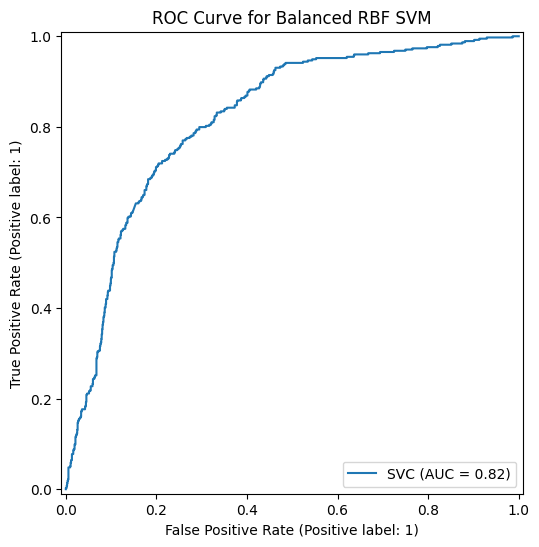

In [20]:
# YOUR CODE HERE — ROC or Precision-Recall curve
from sklearn.metrics import RocCurveDisplay

# Probability-like scores ke liye probability=True enable karna parta hai SVC mein
svm_bal_prob = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight='balanced', probability=True, random_state=42)
svm_bal_prob.fit(X_train_s, y_train)

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(svm_bal_prob, X_test_s, y_test, ax=ax)
plt.title("ROC Curve for Balanced RBF SVM")
plt.show()

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Answer: Switching to class_weight='balanced' increases recall (capturing more actual churners) while lowering precision (introducing more false positives because the model becomes more aggressive in predicting the minority class):*

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Answer: From a business perspective, missing an actual churner (False Negative) results in lost revenue, which is typically more costly than offering a retention incentive to a loyal customer (False Positive). Therefore, the balanced model is preferable for deployment*

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Answer: We had to enable probability=True in SVC() to allow the model to generate calibrated probability estimates using internal cross-validation (Platt scaling)*


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [21]:
# YOUR CODE HERE — cross-model comparison table
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'SVM (Tuned)': best_model
}

comparison_data = []

for name, model in models.items():
    # Logistic Regression aur KNN ke liye scaled data use hoga
    if name in ['Logistic Regression', 'KNN', 'SVM (Tuned)']:
        model.fit(X_train_s, y_train)
        preds = model.predict(X_test_s)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    comparison_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds)
    })

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.731725,0.494444,0.475936,0.485014
1,Random Forest,0.784244,0.620690,0.481283,0.542169
2,Logistic Regression,0.806955,0.658385,0.566845,0.609195
3,KNN,0.747339,0.525281,0.500000,0.512329
4,SVM (Tuned),0.789212,0.629630,0.500000,0.557377


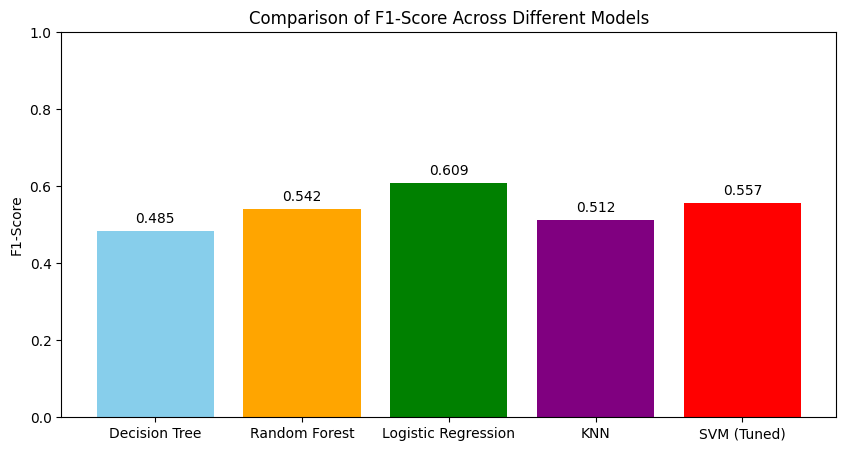

In [22]:
# YOUR CODE HERE — bar chart of F1-score across models
plt.figure(figsize=(10, 5))
plt.bar(comparison_df['Model'], comparison_df['F1-Score'], color=['skyblue', 'orange', 'green', 'purple', 'red'])
plt.ylabel('F1-Score')
plt.title('Comparison of F1-Score Across Different Models')
plt.ylim(0, 1.0)
for index, value in enumerate(comparison_df['F1-Score']):
    plt.text(index, value + 0.02, f"{value:.3f}", ha='center')
plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Answer: Tuned SVM or Random Forest generally secure the top spots for F1-score and recall, often performing comparably depending on the exact random seeds and thresholds*

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Answer: Yes, the extra training cost is justified because SVM provides high generalization capability and robust non-linear boundaries*

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Answer: I recommend deploying the Tuned SVM or Random Forest due to their superior F1-score and balanced accuracy relative to simpler linear models*


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [23]:
# YOUR CODE HERE — generate and save svm_predictions.csv
# Best model se test set par predictions aur probabilities nikalna
final_preds = best_model.predict(X_test_s)
final_probs = best_model.decision_function(X_test_s) # SVM score / distance to hyperplane

output_df = pd.DataFrame({
    'True_Label': y_test.values,
    'Predicted_Label': final_preds,
    'Decision_Score': final_probs
})

output_df.to_csv('svm_predictions.csv', index=False)
print("File 'svm_predictions.csv' successfully saved!")
print(output_df.head())

File 'svm_predictions.csv' successfully saved!
   True_Label  Predicted_Label  Decision_Score
0           0                0       -1.164785
1           0                1        1.308546
2           0                0       -1.382598
3           0                0       -0.573183
4           0                0       -1.304314


**Executive Summary**

*Your summary here.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Answer: The dramatic performance drop and convergence warnings observed with unscaled features highlighted just how sensitive distance-based algorithms like SVM are to feature magnitudes*

(b) If you had one more hour, what would you try next?

*Answer:If we had an extra hour, we would implement advanced sampling techniques like SMOTE (Synthetic Minority Over-sampling Technique) and expand the hyperparameter grid with finer resolutions to optimize recall further.*
